In [3]:
pip install opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.2/79.2 MB 3.5 MB/s eta 0:00:00m eta 0:00:010:00:01
Note: you may need to restart the kernel to use updated packages.


In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [23]:
# 1. Load two sample image files using OpenCV (cv2)
img1 = cv2.imread('sample_img1.png')
img2 = cv2.imread('sample_img2.png')

orig_shape1 = img1.shape
orig_shape2 = img2.shape

# Resize both images to matching dimensions if required
target_size = (400, 300)  # (width, height)
if (img1.shape[1], img1.shape[0]) != target_size:
    img1 = cv2.resize(img1, target_size, interpolation=cv2.INTER_AREA)
if (img2.shape[1], img2.shape[0]) != target_size:
    img2 = cv2.resize(img2, target_size, interpolation=cv2.INTER_AREA)

# 2. Perform weighted image blending (cv2.addWeighted)
alpha = 0.6
beta = 0.4
gamma = 0.0
blended = cv2.addWeighted(img1, alpha, img2, beta, gamma)

# Save individual outputs and a side-by-side verification image
cv2.imwrite('output_img1.png', img1)
cv2.imwrite('output_img2.png', img2)
cv2.imwrite('output_blended.png', blended)

True

In [24]:
# Side-by-side verification montage saved to disk
montage = np.hstack((img1, img2, blended))
cv2.imwrite('verification_montage.png', montage)

# Display side-by-side using matplotlib (converting BGR to RGB for display)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
panels = [
    (cv2.cvtColor(img1, cv2.COLOR_BGR2RGB), f'Input 1 ({img1.shape[1]}x{img1.shape[0]})'),
    (cv2.cvtColor(img2, cv2.COLOR_BGR2RGB), f'Input 2 (Resized {img2.shape[1]}x{img2.shape[0]})'),
    (cv2.cvtColor(blended, cv2.COLOR_BGR2RGB), f'Blended (a={alpha}, b={beta})')
]
for ax, (rgb_img, title) in zip(axes, panels):
    ax.imshow(rgb_img)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('blending_verification.png', dpi=150)
plt.close()

print(f"Original Image 1 shape (H, W, C): {orig_shape1}")
print(f"Original Image 2 shape (H, W, C): {orig_shape2}")
print(f"Aligned shape (H, W, C): {img1.shape}, {img2.shape}, {blended.shape}")
print("Blended pixel intensity stats (min, mean, max):", blended.min(), round(float(blended.mean()), 2), blended.max())

Original Image 1 shape (H, W, C): (300, 400, 3)
Original Image 2 shape (H, W, C): (360, 480, 3)
Aligned shape (H, W, C): (300, 400, 3), (300, 400, 3), (300, 400, 3)
Blended pixel intensity stats (min, mean, max): 16 95.23 225


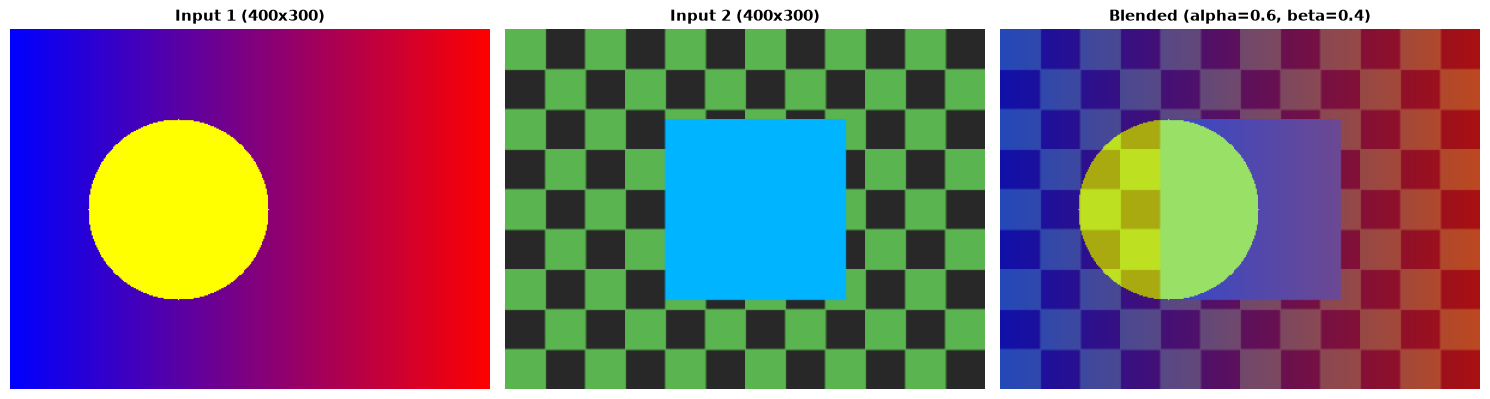

In [25]:
# Display side-by-side (convert BGR -> RGB for Matplotlib display)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
titles = [
    f'Input 1 ({img1.shape[1]}x{img1.shape[0]})',
    f'Input 2 ({img2.shape[1]}x{img2.shape[0]})',
    f'Blended (alpha={alpha}, beta={beta})',
]
images_rgb = [
    cv2.cvtColor(img1, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(img2, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(blended, cv2.COLOR_BGR2RGB),
]

for ax, rgb_img, title in zip(axes, images_rgb, titles):
  ax.imshow(rgb_img)
  ax.set_title(title, fontsize=11, fontweight='bold')
  ax.axis('off')

plt.tight_layout()
plt.show()